In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
df = pd.read_csv("simbad 1795.csv", sep=r";", skiprows=7, engine='python',skipinitialspace=True )

In [3]:
print(df.columns)

Index(['# ', 'dist(asec)', 'identifier             ', 'typ',
       'coord1 (ICRS,J2000/2000)        ', 'radvel    ', 'redshift  ',
       'cz      ', 'Mag U  ', 'Mag B  ', 'Mag V  ', 'Mag R  ', 'Mag I ',
       'spec. type   ', '#bib', '#not', '#Dist', 'distance Q unit',
       'err-        err+     ', 'method ', 'reference     '],
      dtype='object')


In [4]:
lower_limit = [0.065,0.072,0.035,0.043,0.06,0.063]
upper_limit = [0.092,0.105,0.1,0.073,0.08,0.09]
RXC_df=df[(df['typ']=='G  ')] 
# Convert to floats and tidy up column names
RXC_df['radvel'] = pd.to_numeric(RXC_df['radvel    '], errors='coerce')
RXC_df = RXC_df.dropna(subset=['radvel'])
RXC_df['dist(asec)'] = [float(i) for i in RXC_df['dist(asec)']]
RXC_df['redshift'] = [float(i) for i in RXC_df['redshift  ']]
RXC_df['radvel'] = [float(i) for i in RXC_df['radvel']]

# Filter by redshift
z_min, z_max = 0.05, 0.09
RXC_df = RXC_df[(RXC_df['redshift'] > lower_limit[5]) & (RXC_df['redshift'] < upper_limit[5])]
dist = []
from astropy import units as u
from astropy.cosmology import Planck18 as cosmo

dist = []

for i in range(len(df)):
    try:
        ang = RXC_df['dist(asec)'][i] * u.arcsec
        z = RXC_df['redshift'][i]
    
        # convert angular size to kpc
        physical = (ang.to(u.arcmin) * cosmo.kpc_proper_per_arcmin(z)).value
        dist.append(physical)
    
        print(RXC_df['dist(asec)'][i], physical)
    except:
        pass

C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\1014665788.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  RXC_df['radvel'] = pd.to_numeric(RXC_df['radvel    '], errors='coerce')


108.57 144.82323303745883
317.46 398.50570026269406
326.57 434.6640274935918
364.7 470.4077112014331
439.9 580.7688395728698
462.98 581.0055336555756
536.91 696.4690156527539
538.28 690.3492368398477
694.48 890.6772274662583
741.91 936.9160826580377
749.13 967.5003970520576
790.1 1347.5679858118713
807.07 1041.8859011746204
850.03 1132.008384097214
873.98 1109.326882827328
921.27 1387.478833598638
973.78 1225.7879371635443
996.62 1715.511269743119
1043.08 1705.0650592143863
1053.58 1585.2423164385561
1059.0 1358.3719935803304
1060.94 1819.248119291804
1091.6 1469.0288170850001
1227.15 1592.0594889480044
1258.44 1899.0850197011177
1271.01 1632.1819837360351
1278.16 1605.1731936552576
1352.19 1745.607811849418
1482.05 2076.999862508638
1501.75 1960.9641634684874
1692.94 2126.3851841933433
1700.21 2214.197497939359
1734.62 2509.0867605022604


33
33


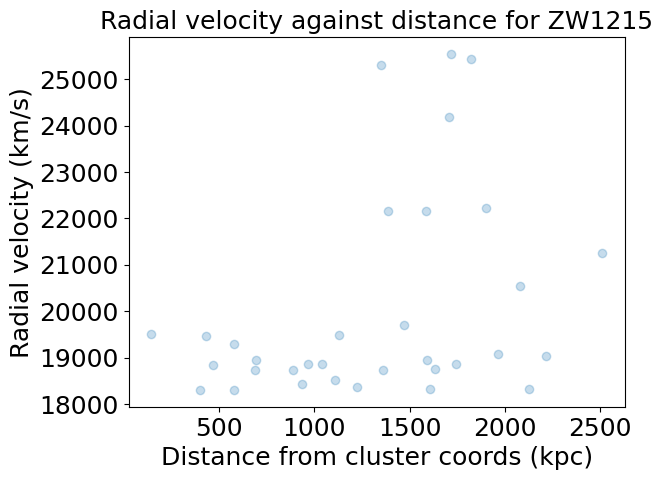

In [6]:

print(len(dist))
print(len(RXC_df['radvel']))
plt.scatter(dist,RXC_df['radvel'], alpha = 0.25)
plt.xlabel('Distancefrom cluster coords (kpc)', fontsize=18)
plt.ylabel('Radial velocity (km/s)', fontsize=18)
plt.title('Radial velocity against distance for ZW1215', fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from astroquery.simbad import Simbad
import astropy.coordinates as coord
import pandas
import scipy
import scipy.stats as stats
import astropy.constants as cons
import scipy.constants as math_cons
from astropy.cosmology import WMAP9 as cosmo
from astropy import units as u
import astropy.cosmology.units as cu
from scipy.optimize import curve_fit


In [11]:
df['#Dist'] = pd.to_numeric(df['#Dist'], errors='coerce')
set = df[(df['#Dist'] > 0)]
set[['distance_value', 'distance_unit']] = set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
set['distance_value'] = pd.to_numeric(set['distance_value'], errors='coerce')

C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\4188375280.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set[['distance_value', 'distance_unit']] = set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\4188375280.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set[['distance_value', 'distance_unit']] = set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\4188375280.py:4: Setting

C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\4258807720.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set['redshift  '] = pd.to_numeric(set['redshift  '], errors='coerce')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\4258807720.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  set['dist(asec)'] = pd.to_numeric(set['dist(asec)'], errors='coerce')


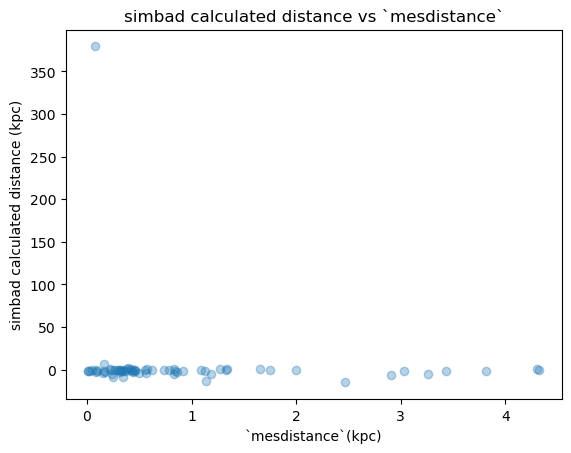

In [12]:

from astropy import units as u
from astropy.cosmology import WMAP9 as cosmo
set['redshift  '] = pd.to_numeric(set['redshift  '], errors='coerce')
set['dist(asec)'] = pd.to_numeric(set['dist(asec)'], errors='coerce')
clean = set.dropna(subset=['dist(asec)', 'redshift  '])

dist_kpc = ((clean['dist(asec)'].values * u.arcsec).to(u.arcmin)* cosmo.kpc_proper_per_arcmin(clean['redshift  '].values)).value
plt.scatter(clean['distance_value']/1000,dist_kpc,alpha=0.33)
plt.xlabel("`mesdistance`(kpc)")
plt.ylabel("simbad calculated distance (kpc)")
plt.title('simbad calculated distance vs `mesdistance`')
plt.show()

C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\574867415.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_df['radvel'] = pd.to_numeric(df['radvel    '], errors='coerce')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\574867415.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_df['#Dist'] = pd.to_numeric(other_df['#Dist'], errors='coerce')


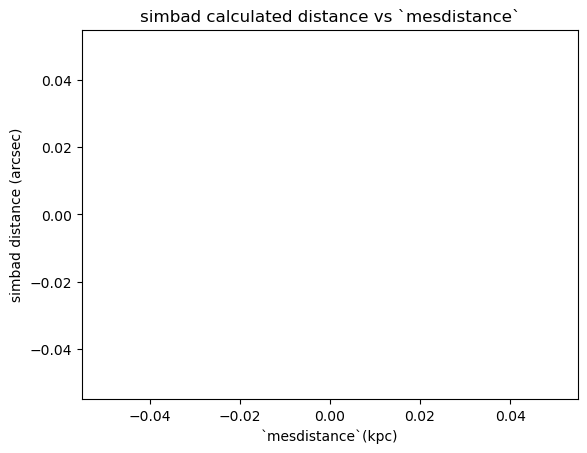

C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\574867415.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_set[['distance_value', 'distance_unit']] = new_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\574867415.py:33: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  new_set[['distance_value', 'distance_unit']] = new_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\57486741

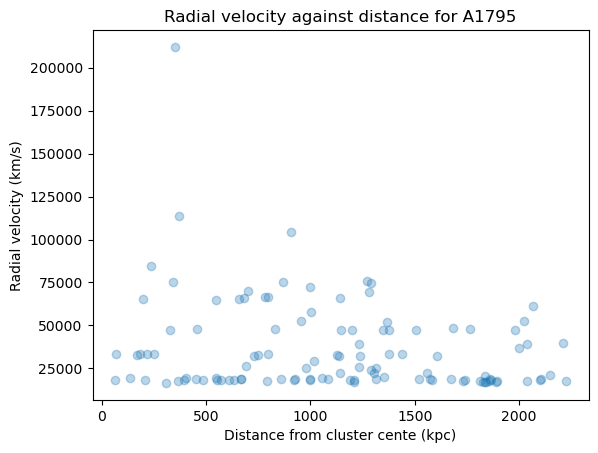

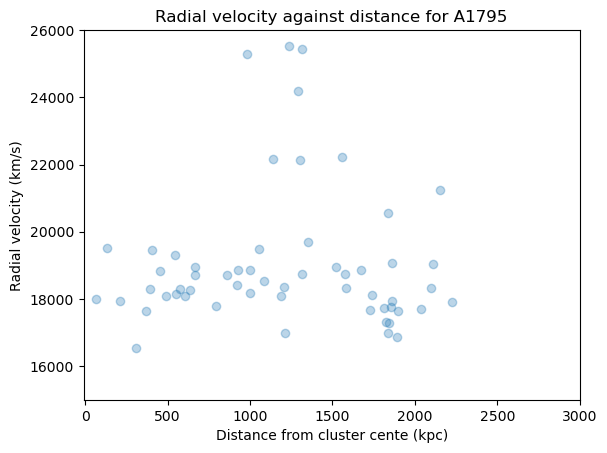

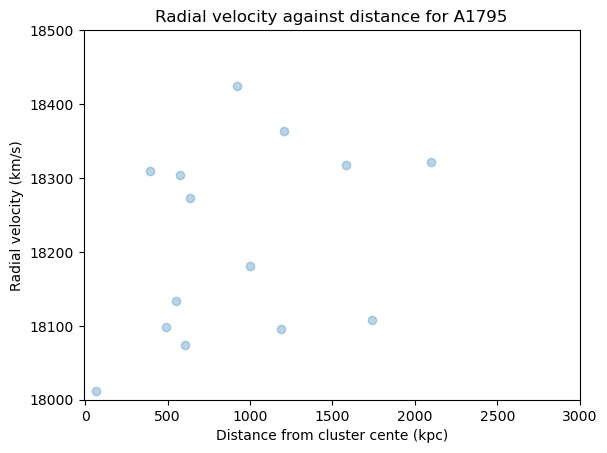

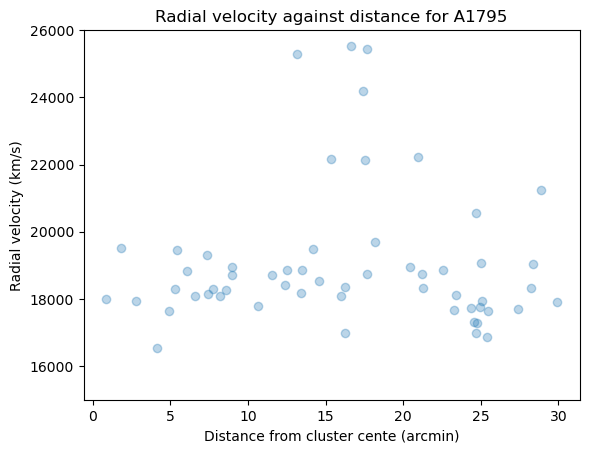

In [13]:
new_df = df[(df['typ']=='G  ')] 
new_df['radvel'] = pd.to_numeric(df['radvel    '], errors='coerce')
new_df = new_df.dropna(subset=['radvel'])
new_df['dist(asec)'] = [float(i) for i in new_df['dist(asec)']]
new_df['redshift'] = [float(i) for i in new_df['redshift  ']]
new_df['radvel'] = [float(i) for i in new_df['radvel']]

other_df = df[(df['typ']=='G  ')] 
other_df['#Dist'] = pd.to_numeric(other_df['#Dist'], errors='coerce')
other_set = other_df[(other_df['#Dist'] > 0)]
other_set[['distance_value', 'distance_unit']] = other_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
other_set['distance_value'] = pd.to_numeric(other_set['distance_value'], errors='coerce')

plt.scatter(other_set['distance_value']/1000,other_set['dist(asec)'],alpha = 0.33)
plt.xlabel("`mesdistance`(kpc)")
plt.ylabel("simbad distance (arcsec)")
plt.title('simbad calculated distance vs `mesdistance`')
plt.show()

# Filter by redshift
dist = []
from astropy import units as u
from astropy.cosmology import Planck18 as cosmo

dist = []
lower_limit = [0.065,0.072,0.035,0.043,0.06,0.063]
upper_limit = [0.092,0.105,0.1,0.073,0.08,0.09]


new_df['#Dist'] = pd.to_numeric(new_df['#Dist'], errors='coerce')
new_set = new_df[(new_df['redshift'] > 0.055)] #& (new_df['redshift'] < upper_limit[0])]

new_set[['distance_value', 'distance_unit']] = new_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
new_set['distance_value'] = pd.to_numeric(new_set['distance_value'], errors='coerce')
for i in range(len(df)):
    try:
        ang = new_set['dist(asec)'][i] * u.arcsec
        #z = new_set['redshift'][i]
        z=0.0622
        # convert angular size to kpc
        physical = (ang.to(u.arcmin) * cosmo.kpc_proper_per_arcmin(z)).value
        dist.append(physical)
    
    except:
        pass

plt.scatter(dist,new_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)')
plt.ylabel('Radial velocity (km/s)')
plt.title('Radial velocity against distance for A1795')
plt.show()

plt.scatter(dist,new_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)')
plt.ylabel('Radial velocity (km/s)')
plt.title('Radial velocity against distance for A1795')
plt.xlim(-10,3000)
plt.ylim(15000,26000)
plt.show()

plt.scatter(dist,new_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)')
plt.ylabel('Radial velocity (km/s)')
plt.title('Radial velocity against distance for A1795')
plt.xlim(-10,3000)
plt.ylim(18000,18500)
plt.show()

plt.scatter(new_set['dist(asec)']/60,new_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (arcmin)')
plt.ylabel('Radial velocity (km/s)')
plt.title('Radial velocity against distance for A1795')
plt.ylim(15000,26000)
plt.show()

C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\2613149678.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_df['radvel'] = pd.to_numeric(other_df['radvel    '], errors='coerce')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\2613149678.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_set[['distance_value', 'distance_unit']] = other_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\2613149678.py:5: SettingWithCopyWarning: 


380 380


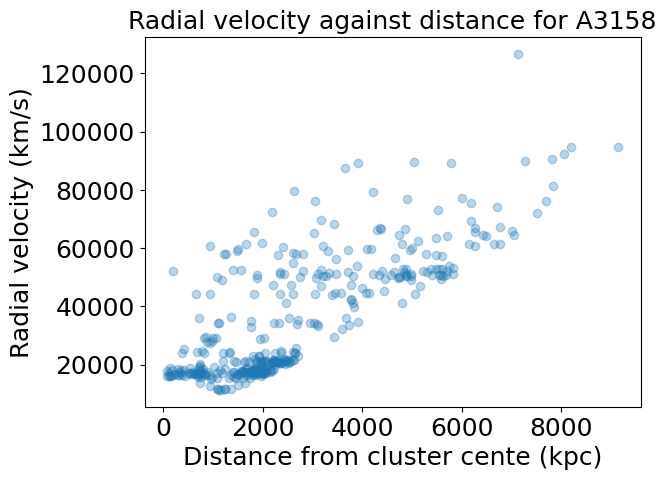

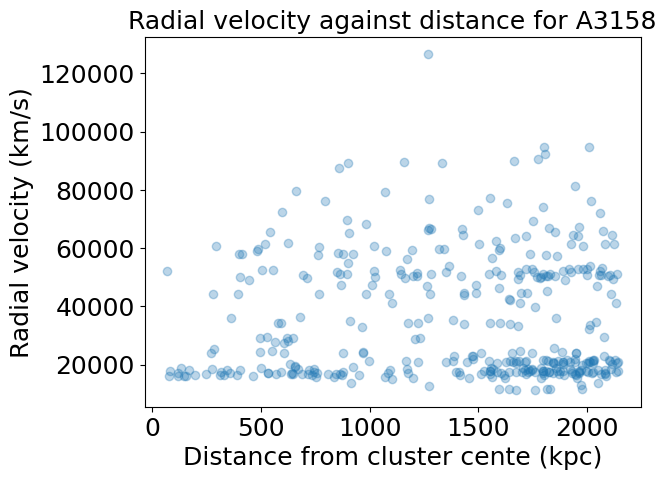

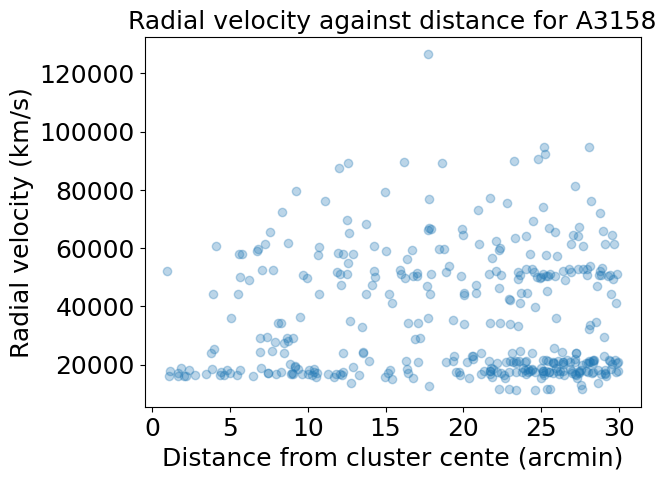

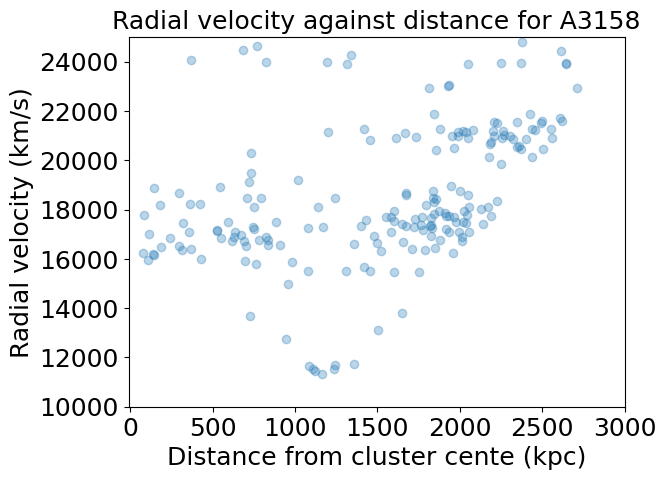

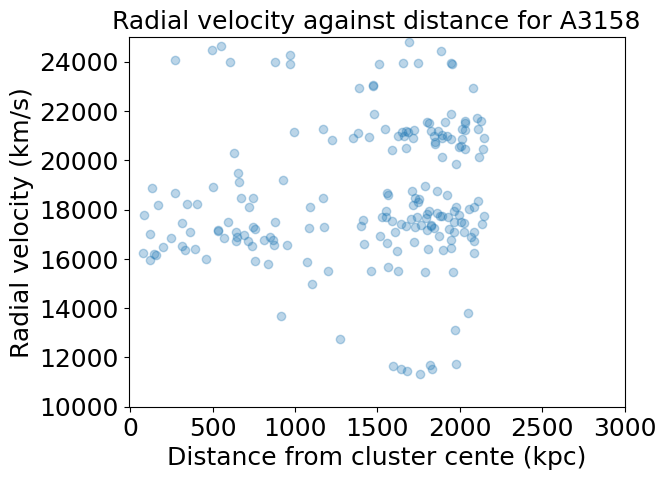

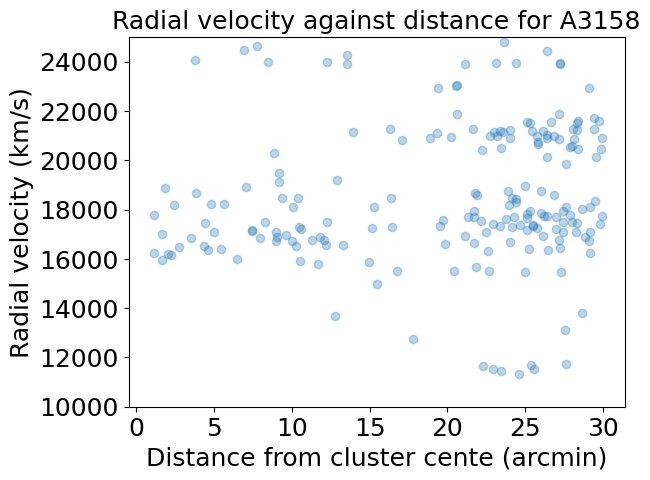

"\nplt.scatter(dist,other_set['radvel'],alpha=0.3)\nplt.xlabel('Distance from cluster cente (kpc)',fontsize=18)\nplt.ylabel('Radial velocity (km/s)',fontsize=18)\nplt.title('Radial velocity against distance for A3158',fontsize=18)\nplt.xticks(fontsize=18)\nplt.yticks(fontsize=18)\nplt.xlim(-10,2500)\nplt.ylim(15000,20000)\nplt.show()\n"

In [14]:
df_31 = pd.read_csv("simbad 3158.csv", sep=r";", skiprows=7, engine='python',skipinitialspace=True )
other_df = df_31[(df_31['typ']=='G  ')] 
other_df['radvel'] = pd.to_numeric(other_df['radvel    '], errors='coerce')
other_set = other_df.dropna(subset=['radvel'])
other_set[['distance_value', 'distance_unit']] = other_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
other_set['distance_value'] = pd.to_numeric(other_set['distance_value'], errors='coerce')



other_set['dist(asec)'] = [float(i) for i in other_set['dist(asec)']]
other_set['redshift'] = [float(i) for i in other_set['redshift  ']]
other_set['radvel'] = [float(i) for i in other_set['radvel']]

# Filter by redshift
dist = []
from astropy import units as u
from astropy.cosmology import Planck18 as cosmo

dist = []
distv2 = []
lower_limit = [0.065,0.072,0.035,0.043,0.06,0.063]
upper_limit = [0.092,0.105,0.1,0.073,0.08,0.09]

new_df['#Dist'] = pd.to_numeric(new_df['#Dist'], errors='coerce')
new_set = new_df[(new_df['redshift'] > 0.055)] #& (new_df['redshift'] < upper_limit[0])]
new_set[['distance_value', 'distance_unit']] = new_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
new_set['distance_value'] = pd.to_numeric(new_set['distance_value'], errors='coerce')
for i in range(len(df_31)):
    try:
        ang = other_set['dist(asec)'][i] * u.arcsec
        z = other_set['redshift'][i]
        physical = (ang.to(u.arcmin) * cosmo.kpc_proper_per_arcmin(z)).value
        dist.append(physical)   
    except:
        pass

for i in range(len(df_31)):
    try:
        ang = other_set['dist(asec)'][i] * u.arcsec
        z=0.0597
        physical = (ang.to(u.arcmin) * cosmo.kpc_proper_per_arcmin(z)).value
        distv2.append(physical)
    
    except:
        pass
print(len(dist),len(other_set['radvel']))
plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A3158',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()

plt.scatter(distv2,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A3158',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()

plt.scatter(other_set['dist(asec)']/60,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (arcmin)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A3158',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()


plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A3158',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.xlim(-10,3000)
plt.ylim(10000,25000)
plt.show()

plt.scatter(distv2,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A3158',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.xlim(-10,3000)
plt.ylim(10000,25000)
plt.show()

plt.scatter(other_set['dist(asec)']/60,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (arcmin)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A3158',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
#plt.xlim(-10,3500)
plt.ylim(10000,25000)
plt.show()

C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\2293664623.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_df['radvel'] = pd.to_numeric(other_df['radvel    '], errors='coerce')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\2293664623.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_set[['distance_value', 'distance_unit']] = other_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\2293664623.py:5: SettingWithCopyWarning: 


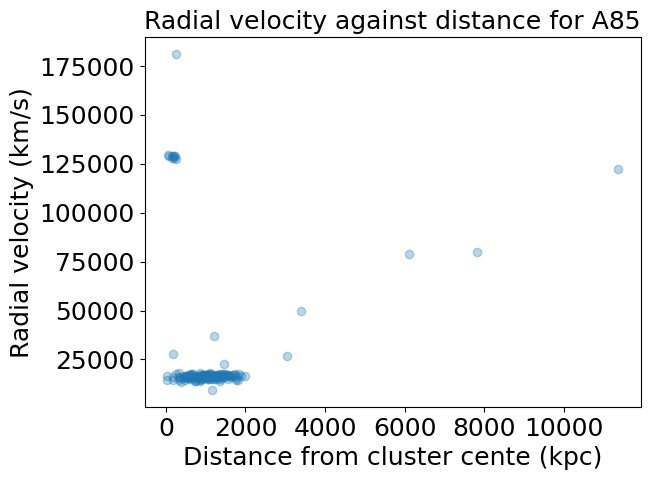

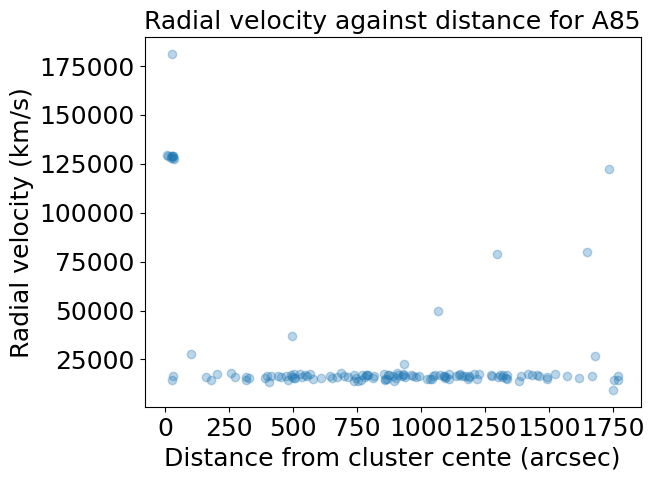

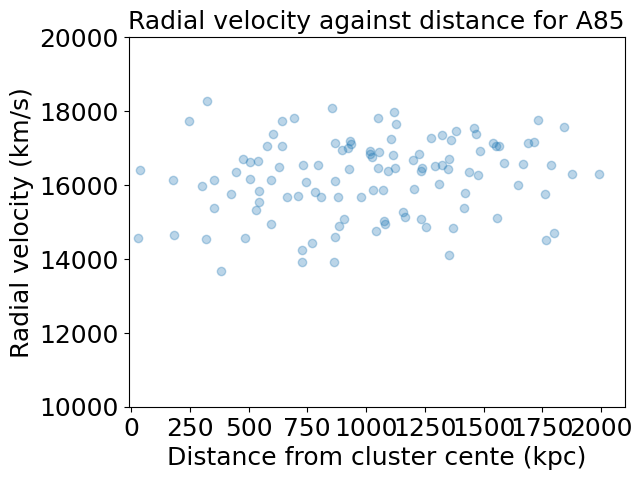

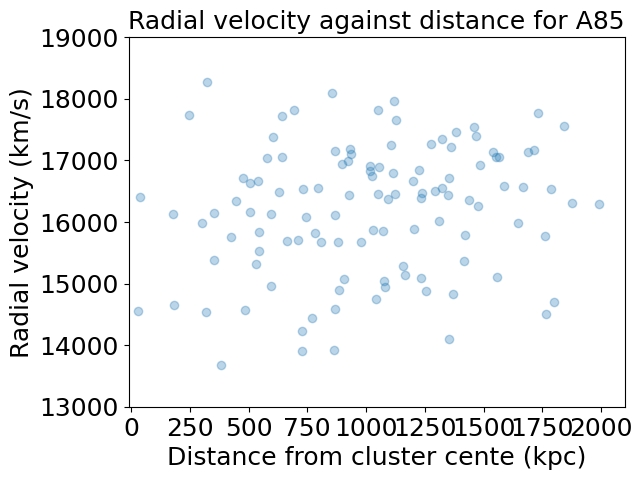

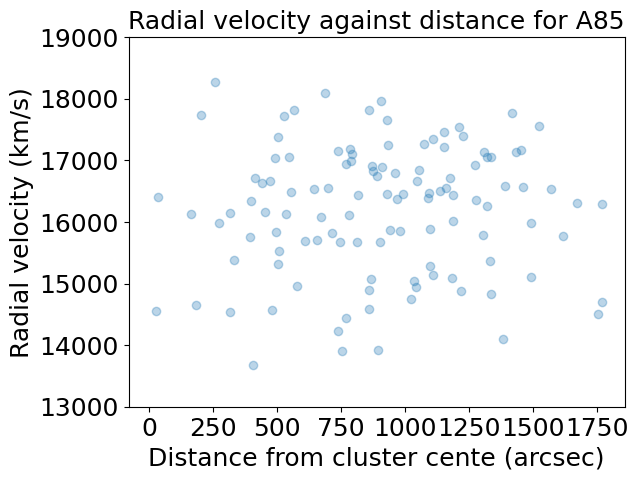

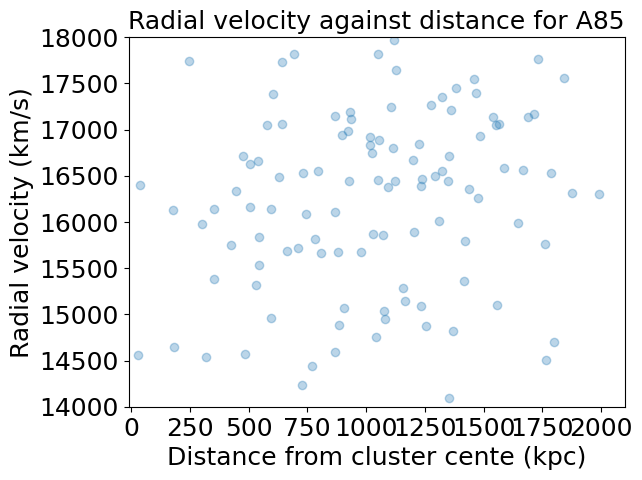

In [15]:
df_85 = pd.read_csv("simbad 85.csv", sep=r";", skiprows=7, engine='python',skipinitialspace=True )
other_df = df_85[(df_85['typ']=='G  ')] 
other_df['radvel'] = pd.to_numeric(other_df['radvel    '], errors='coerce')
other_set = other_df.dropna(subset=['radvel'])
other_set[['distance_value', 'distance_unit']] = other_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
other_set['distance_value'] = pd.to_numeric(other_set['distance_value'], errors='coerce')

other_set['dist(asec)'] = [float(i) for i in other_set['dist(asec)']]
other_set['redshift'] = [float(i) for i in other_set['redshift  ']]
other_set['radvel'] = [float(i) for i in other_set['radvel']]

# Filter by redshift
dist = []
from astropy import units as u
from astropy.cosmology import Planck18 as cosmo
dist = []
lower_limit = [0.065,0.072,0.035,0.043,0.06,0.063]
upper_limit = [0.092,0.105,0.1,0.073,0.08,0.09]


new_df['#Dist'] = pd.to_numeric(new_df['#Dist'], errors='coerce')
new_set = new_df[(new_df['redshift'] > 0.055)] #& (new_df['redshift'] < upper_limit[0])]
new_set[['distance_value', 'distance_unit']] = new_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
new_set['distance_value'] = pd.to_numeric(new_set['distance_value'], errors='coerce')
for i in range(len(df_85)):
    try:
        ang = other_set['dist(asec)'][i] * u.arcsec
        z = other_set['redshift'][i]
        physical = (ang.to(u.arcmin) * cosmo.kpc_proper_per_arcmin(z)).value
        dist.append(physical)    
    except:
        pass

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A85',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()
plt.scatter(other_set['dist(asec)'],other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (arcsec)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A85',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A85',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.xlim(-10,2100)
plt.ylim(10000,20000)
plt.show()

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A85',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.xlim(-10,2100)
plt.ylim(13000,19000)
plt.show()
plt.scatter(other_set['dist(asec)'],other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (arcsec)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A85',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
#plt.xlim(-10,2100)
plt.ylim(13000,19000)
plt.show()

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A85',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.xlim(-10,2100)
plt.ylim(14000,18000)
plt.show()

C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\4234488134.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_df['radvel'] = pd.to_numeric(other_df['radvel    '], errors='coerce')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\4234488134.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_set[['distance_value', 'distance_unit']] = other_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\4234488134.py:5: SettingWithCopyWarning: 


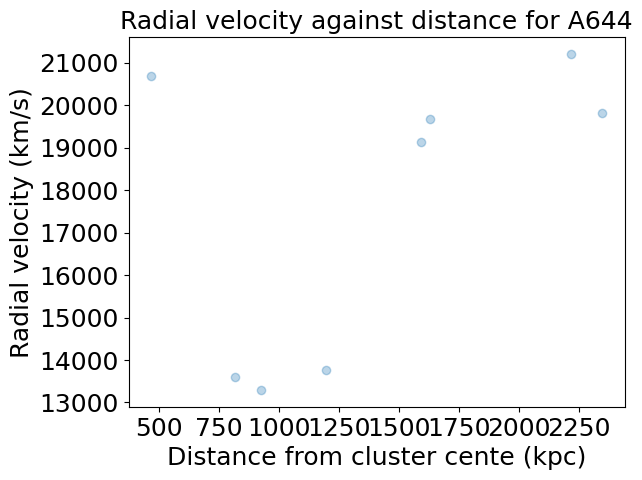

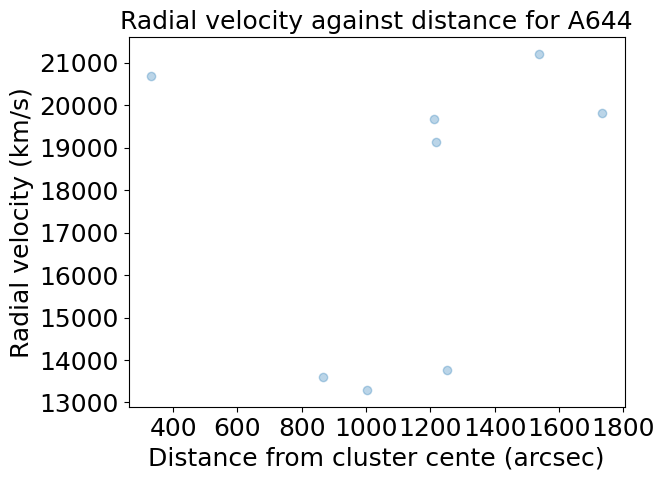

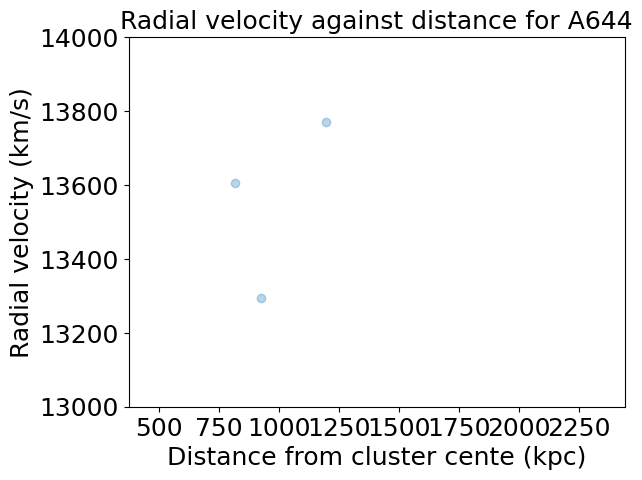

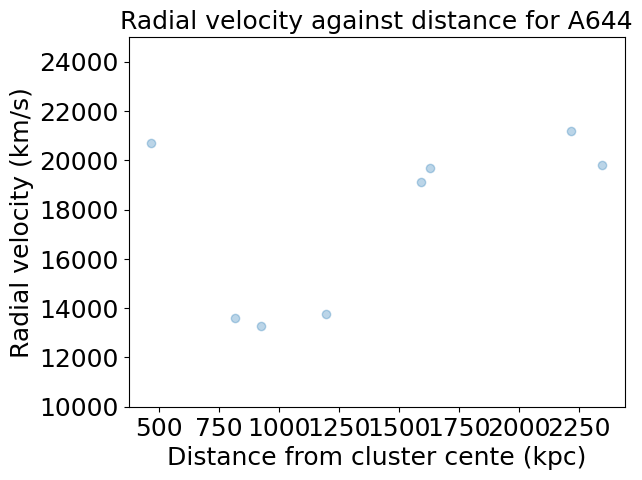

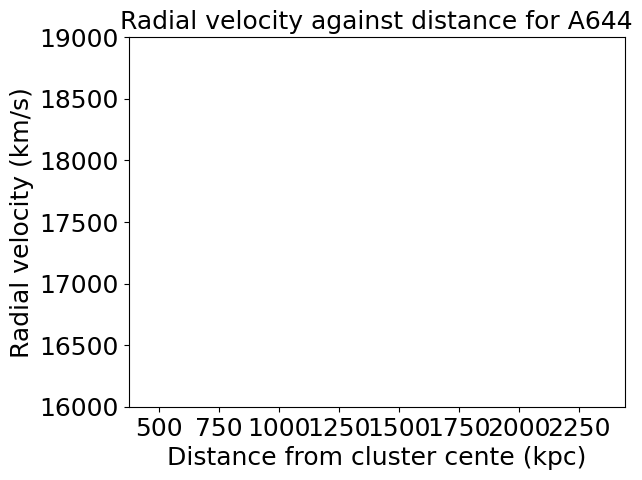

In [16]:
df_644 = pd.read_csv("simbad 644.csv", sep=r";", skiprows=7, engine='python',skipinitialspace=True )
other_df = df_644[(df_644['typ']=='G  ')] 
other_df['radvel'] = pd.to_numeric(other_df['radvel    '], errors='coerce')
other_set = other_df.dropna(subset=['radvel'])
other_set[['distance_value', 'distance_unit']] = other_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
other_set['distance_value'] = pd.to_numeric(other_set['distance_value'], errors='coerce')

other_set['dist(asec)'] = [float(i) for i in other_set['dist(asec)']]
other_set['redshift'] = [float(i) for i in other_set['redshift  ']]
other_set['radvel'] = [float(i) for i in other_set['radvel']]

# Filter by redshift
dist = []
from astropy import units as u
from astropy.cosmology import Planck18 as cosmo

dist = []
lower_limit = [0.065,0.072,0.035,0.043,0.06,0.063]
upper_limit = [0.092,0.105,0.1,0.073,0.08,0.09]


new_df['#Dist'] = pd.to_numeric(new_df['#Dist'], errors='coerce')
new_set = new_df[(new_df['redshift'] > 0.055)] #& (new_df['redshift'] < upper_limit[0])]
new_set[['distance_value', 'distance_unit']] = new_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
new_set['distance_value'] = pd.to_numeric(new_set['distance_value'], errors='coerce')
for i in range(len(df_644)):
    try:
        ang = other_set['dist(asec)'][i] * u.arcsec
        z = other_set['redshift'][i]
        physical = (ang.to(u.arcmin) * cosmo.kpc_proper_per_arcmin(z)).value
        dist.append(physical)
    except:
        pass

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A644',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()
plt.scatter(other_set['dist(asec)'],other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (arcsec)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A644',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A644',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
#plt.xlim(-10,3000)
plt.ylim(13000,14000)
plt.show()

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A644',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
#plt.xlim(-10,3000)
plt.ylim(10000,25000)
plt.show()

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A644',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
#plt.xlim(-10,3000)
plt.ylim(16000,19000)
plt.show()

C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\2609175737.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_df['radvel'] = pd.to_numeric(other_df['radvel   '], errors='coerce')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\2609175737.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_set[['distance_value', 'distance_unit']] = other_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\2609175737.py:5: SettingWithCopyWarning: 
A

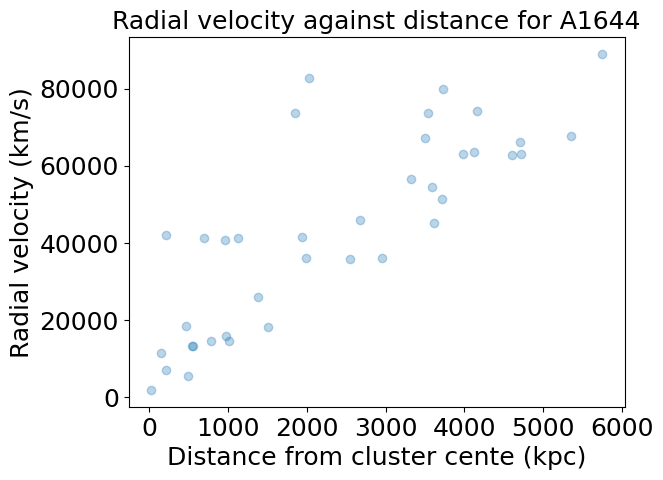

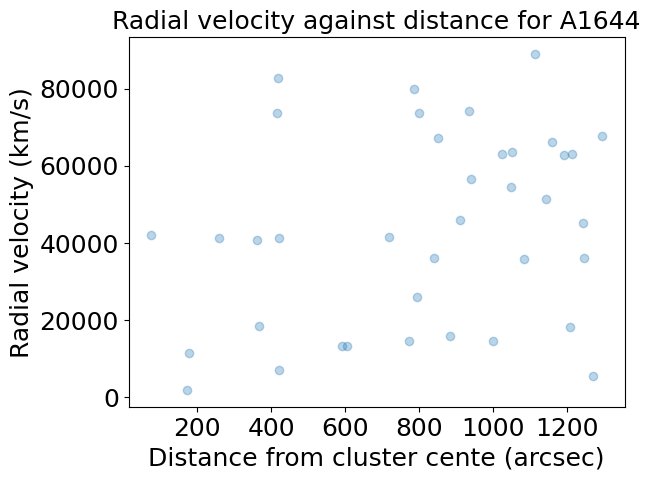

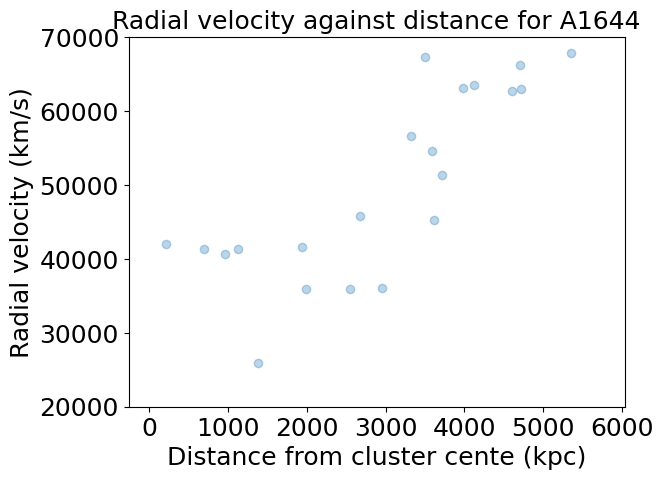

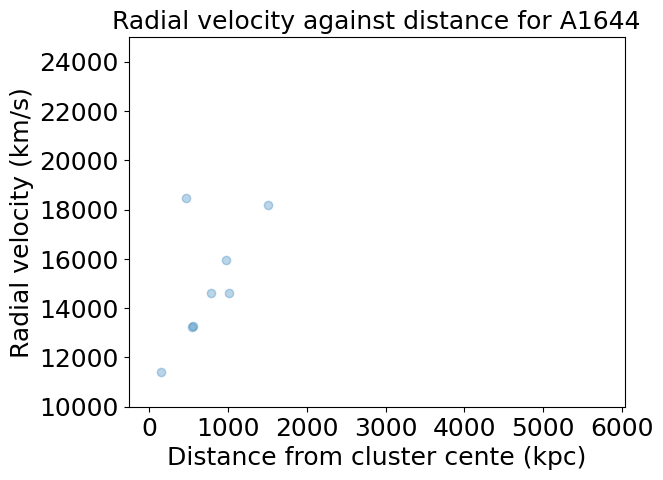

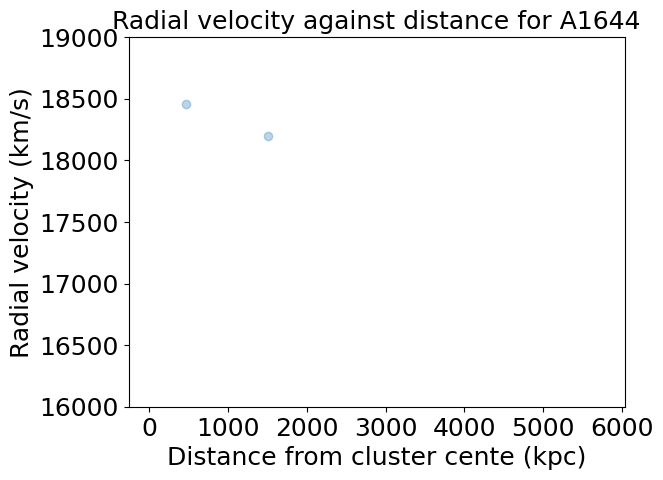

In [17]:
df_1644 = pd.read_csv("simbad 1644.csv", sep=r";", skiprows=7, engine='python',skipinitialspace=True )
other_df = df_1644[(df_1644['typ']=='G  ')] 
other_df['radvel'] = pd.to_numeric(other_df['radvel   '], errors='coerce')
other_set = other_df.dropna(subset=['radvel'])
other_set[['distance_value', 'distance_unit']] = other_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
other_set['distance_value'] = pd.to_numeric(other_set['distance_value'], errors='coerce')

other_set['dist(asec)'] = [float(i) for i in other_set['dist(asec)']]
other_set['redshift'] = [float(i) for i in other_set['redshift  ']]
other_set['radvel'] = [float(i) for i in other_set['radvel']]

# Filter by redshift
dist = []
from astropy import units as u
from astropy.cosmology import Planck18 as cosmo

dist = []
lower_limit = [0.065,0.072,0.035,0.043,0.06,0.063]
upper_limit = [0.092,0.105,0.1,0.073,0.08,0.09]


new_df['#Dist'] = pd.to_numeric(new_df['#Dist'], errors='coerce')
new_set = new_df[(new_df['redshift'] > 0.055)] #& (new_df['redshift'] < upper_limit[0])]
new_set[['distance_value', 'distance_unit']] = new_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
new_set['distance_value'] = pd.to_numeric(new_set['distance_value'], errors='coerce')
for i in range(len(df_1644)):
    try:
        ang = other_set['dist(asec)'][i] * u.arcsec
        z = other_set['redshift'][i]
        physical = (ang.to(u.arcmin) * cosmo.kpc_proper_per_arcmin(z)).value
        dist.append(physical)
    except:
        pass

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A1644',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()
plt.scatter(other_set['dist(asec)'],other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (arcsec)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A1644',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A1644',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
#plt.xlim(-10,3000)
plt.ylim(20000,70000)
plt.show()

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A1644',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
#plt.xlim(-10,3000)
plt.ylim(10000,25000)
plt.show()

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A1644',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
#plt.xlim(-10,3000)
plt.ylim(16000,19000)
plt.show()

C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\816620926.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_df['radvel'] = pd.to_numeric(other_df['radvel    '], errors='coerce')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\816620926.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  other_set[['distance_value', 'distance_unit']] = other_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
C:\Users\Katie\AppData\Local\Temp\ipykernel_26684\816620926.py:5: SettingWithCopyWarning: 
A v

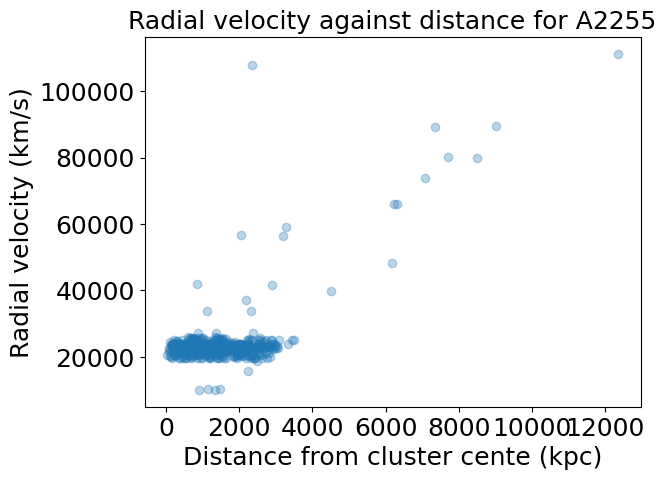

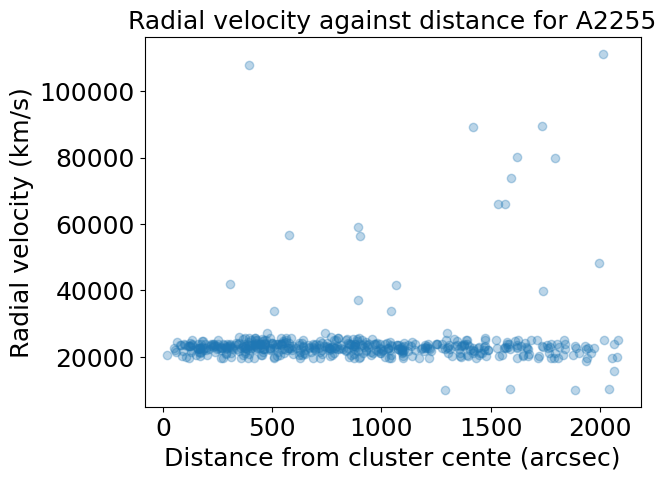

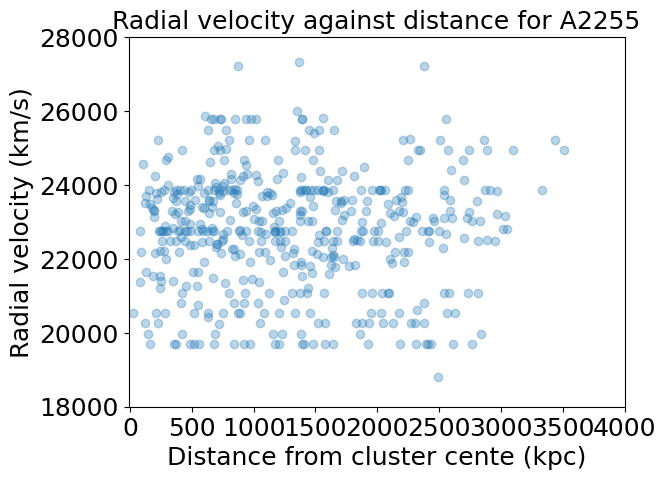

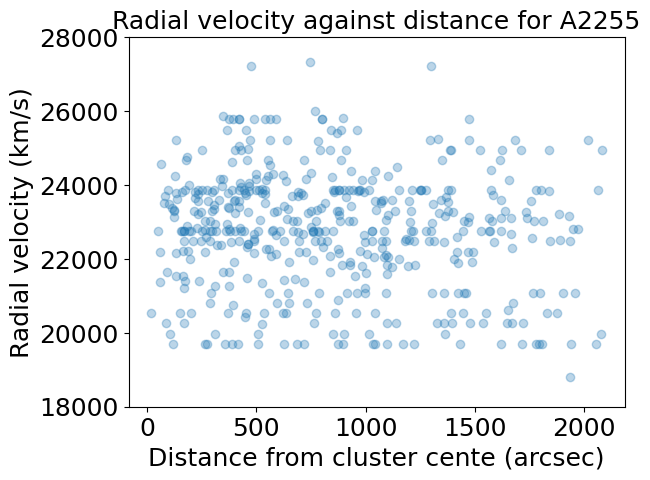

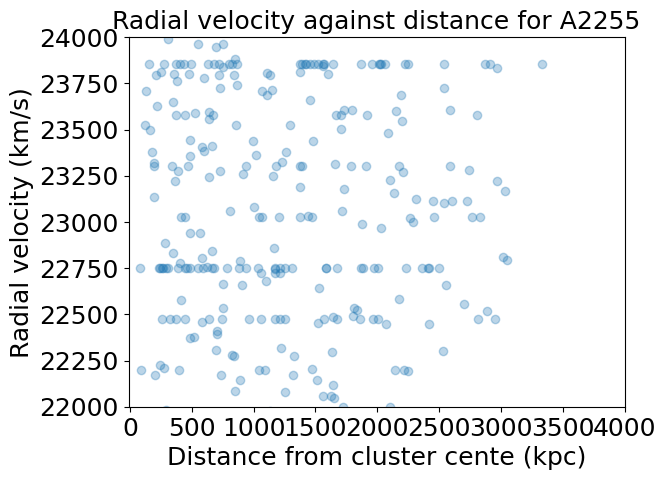

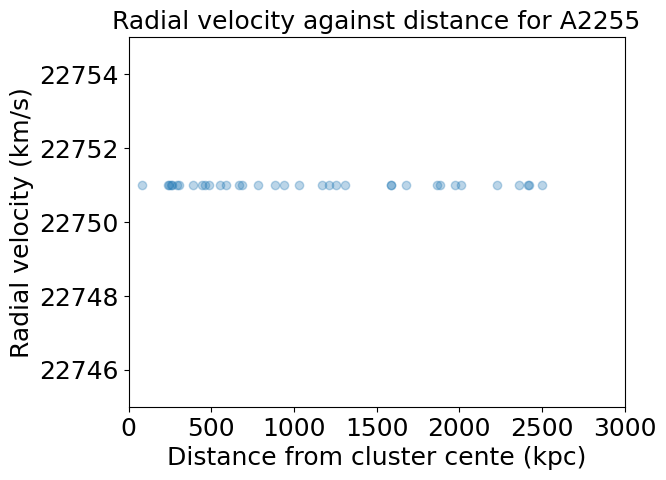

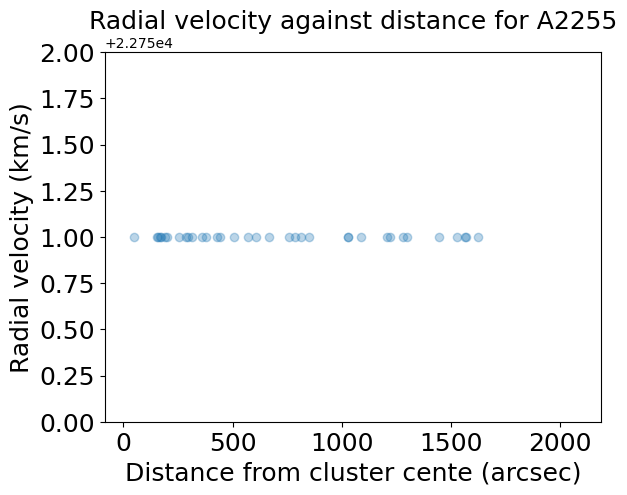

In [18]:
df_2255 = pd.read_csv("simbad 2255.csv", sep=r";", skiprows=7, engine='python',skipinitialspace=True )
other_df = df_2255[(df_2255['typ']=='G  ')] 
other_df['radvel'] = pd.to_numeric(other_df['radvel    '], errors='coerce')
other_set = other_df.dropna(subset=['radvel'])
other_set[['distance_value', 'distance_unit']] = other_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
other_set['distance_value'] = pd.to_numeric(other_set['distance_value'], errors='coerce')

other_set['dist(asec)'] = [float(i) for i in other_set['dist(asec)']]
other_set['redshift'] = [float(i) for i in other_set['redshift  ']]
other_set['radvel'] = [float(i) for i in other_set['radvel']]

# Filter by redshift
dist = []
from astropy import units as u
from astropy.cosmology import Planck18 as cosmo

dist = []
lower_limit = [0.065,0.072,0.035,0.043,0.06,0.063]
upper_limit = [0.092,0.105,0.1,0.073,0.08,0.09]

new_df['#Dist'] = pd.to_numeric(new_df['#Dist'], errors='coerce')
new_set = new_df[(new_df['redshift'] > 0.055)] #& (new_df['redshift'] < upper_limit[0])]
new_set[['distance_value', 'distance_unit']] = new_set['distance Q unit'].str.extract(r'([\d\.]+)\s*([A-Za-z]+)')
new_set['distance_value'] = pd.to_numeric(new_set['distance_value'], errors='coerce')
for i in range(len(df_2255)):
    try:
        ang = other_set['dist(asec)'][i] * u.arcsec
        z = other_set['redshift'][i]
        physical = (ang.to(u.arcmin) * cosmo.kpc_proper_per_arcmin(z)).value
        dist.append(physical)
    except:
        pass

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A2255',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()
plt.scatter(other_set['dist(asec)'],other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (arcsec)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A2255',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A2255',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.xlim(-10,4000)
plt.ylim(18000,28000)
plt.show()
plt.scatter(other_set['dist(asec)'],other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (arcsec)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.ylim(18000,28000)
plt.title('Radial velocity against distance for A2255',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A2255',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.xlim(-10,4000)
plt.ylim(22000,24000)
plt.show()

plt.scatter(dist,other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (kpc)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.title('Radial velocity against distance for A2255',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.xlim(0,3000)
plt.ylim(22745,22755)
plt.show()
plt.scatter(other_set['dist(asec)'],other_set['radvel'],alpha=0.3)
plt.xlabel('Distance from cluster cente (arcsec)',fontsize=18)
plt.ylabel('Radial velocity (km/s)',fontsize=18)
plt.ylim(22750,22752)
plt.title('Radial velocity against distance for A2255',fontsize=18)
plt.xticks(fontsize=18)
plt.yticks(fontsize=18)
plt.show()